# Pipeline Completo: ETL, EDA y Preprocesamiento de Imágenes de Placas Solares

Este notebook está estructurado de forma modular mediante funciones reutilizables:
1. **Extracción (Web Scraping con Selenium)**: Descarga opcional de imágenes adicionales limpias.
2. **Construcción del Dataset**: Almacenamiento eficiente mediante **rutas relativas** y lectura ligera de cabeceras (sin guardar objetos pesados en RAM).
3. **EDA (Análisis Exploratorio de Datos)**: Calidad del dato, balance de splits, distribuciones de resolución, outliers por IQR, correlaciones y visualización al vuelo.
4. **Preprocesamiento para Modelado**:
   - **Opción A (Machine Learning Clásico / Tabular)**: Extracción de descriptores visuales de color (RGB/HSV) y textura superficial + Escalado sin *data leakage*.
   - **Opción B (Deep Learning / PyTorch)**: `Dataset` y `DataLoaders` con redimensionado, *Data Augmentation* geométrico y normalización.

In [8]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_theme(style="whitegrid")

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

## 1. Extracción con Selenium (Imágenes Extra)

In [9]:
from pixabay_scraper import scrape_extra_solar_images

# Descomentar si se desea volver a ejecutar la descarga:
scrape_extra_solar_images(output_dir="solar_panel_images", max_images=20, scrolls=4)

Abriendo https://pixabay.com/images/search/solar%20panel/...
Encontrada [1/20]: free photovoltaic system solar photo and picture...
Encontrada [2/20]: free solar panel photo and picture...
Encontrada [3/20]: free solar system roof photo and picture...
Encontrada [4/20]: free photovoltaic nature photo and picture...
Encontrada [5/20]: free panel solar photo and picture...
Encontrada [6/20]: free ai generated solar system illustration and pi...
Encontrada [7/20]: free solar roof photo and picture...
Encontrada [8/20]: free photovoltaic photovoltaic system photo and pi...
Encontrada [9/20]: free solar cell solar panel photo and picture...
Encontrada [10/20]: free solar energy solar panels photo and picture...
Encontrada [11/20]: free photovoltaic system solar photo and picture...
Encontrada [12/20]: free solar panels photo and picture...
Encontrada [13/20]: free solar panels renewable energy vector and pict...
Encontrada [14/20]: free solar energy solar system photo and picture...
Encontr

['solar_panel_images/solar_panel_01.jpg',
 'solar_panel_images/solar_panel_02.jpg',
 'solar_panel_images/solar_panel_03.jpg',
 'solar_panel_images/solar_panel_04.jpg',
 'solar_panel_images/solar_panel_05.jpg',
 'solar_panel_images/solar_panel_06.jpg',
 'solar_panel_images/solar_panel_08.jpg',
 'solar_panel_images/solar_panel_09.jpg',
 'solar_panel_images/solar_panel_10.jpg',
 'solar_panel_images/solar_panel_11.jpg',
 'solar_panel_images/solar_panel_12.jpg',
 'solar_panel_images/solar_panel_13.png',
 'solar_panel_images/solar_panel_14.jpg',
 'solar_panel_images/solar_panel_15.jpg']

## 2. Construcción del Dataset con Rutas Relativas y Metadatos

In [10]:
from solar_dataset import build_solar_dataframe

In [11]:
df = build_solar_dataframe()
df.head(10)

DataFrame creado y guardado en 'data/pvsoiling_dataframe.pkl' con 1714 filas.


,split,ruta_imagen,filename,extension,source,es_sucio,width,height,aspect_ratio,n_pixels,image_mode
0,train,PVSDL_DATASET/train/city_0001_0.jpg,city_0001_0.jpg,.jpg,pvdl_dataset,0,474,338,1.4024,160212,RGB
1,train,PVSDL_DATASET/train/city_0002_0.jpg,city_0002_0.jpg,.jpg,pvdl_dataset,0,537,387,1.3876,207819,RGB
2,train,PVSDL_DATASET/train/city_0003_0.jpg,city_0003_0.jpg,.jpg,pvdl_dataset,0,608,382,1.5916,232256,RGB
3,train,PVSDL_DATASET/train/city_0004_0.jpg,city_0004_0.jpg,.jpg,pvdl_dataset,0,562,362,1.5525,203444,RGB
4,train,PVSDL_DATASET/train/city_0005_0.jpg,city_0005_0.jpg,.jpg,pvdl_dataset,0,242,353,0.6856,85426,RGB
5,train,PVSDL_DATASET/train/city_0007_0.jpg,city_0007_0.jpg,.jpg,pvdl_dataset,0,571,361,1.5817,206131,RGB
6,train,PVSDL_DATASET/train/city_0008_0.jpg,city_0008_0.jpg,.jpg,pvdl_dataset,0,577,370,1.5595,213490,RGB
7,train,PVSDL_DATASET/train/city_0009_0.jpg,city_0009_0.jpg,.jpg,pvdl_dataset,0,591,377,1.5676,222807,RGB
8,train,PVSDL_DATASET/train/city_0010_0.jpg,city_0010_0.jpg,.jpg,pvdl_dataset,0,225,311,0.7235,69975,RGB
9,train,PVSDL_DATASET/train/city_0011_0.jpg,city_0011_0.jpg,.jpg,pvdl_dataset,0,510,318,1.6038,162180,RGB


## 3. Análisis Exploratorio de Datos (EDA)

In [12]:
from eda import (
    check_duplicate_images,
    eda_data_quality,
    eda_outliers_and_correlations,
    eda_plot_distributions,
    eda_plot_sample_images,
)

In [13]:
eda_data_quality(df)

=== 1. DIMENSIONES, TIPOS Y VALORES NULOS ===
Filas: 1714 | Columnas: 11

                 Tipo  Nulos
split          object      0
ruta_imagen    object      0
filename       object      0
extension      object      0
source         object      0
es_sucio        int64      0
width           int64      0
height          int64      0
aspect_ratio  float64      0
n_pixels        int64      0
image_mode     object      0

Duplicados completos: 0
Duplicados en 'ruta_imagen': 0
Extensiones: {'.jpg': 1713, '.png': 1}
Modos de imagen: {'RGB': 1713, 'RGBA': 1}

=== 2. DISTRIBUCIÓN GLOBAL DE LA CLASE OBJETIVO ===
          Cantidad  Porcentaje (%)
es_sucio                          
0             1020           59.51
1              694           40.49

=== 3. DISTRIBUCIÓN POR SPLIT Y CLASE ===
es_sucio  Limpio (0)  Sucio (1)  Total  % Sucio
split                                          
test             141        114    255    44.71
train            736        468   1204    38.87
val          

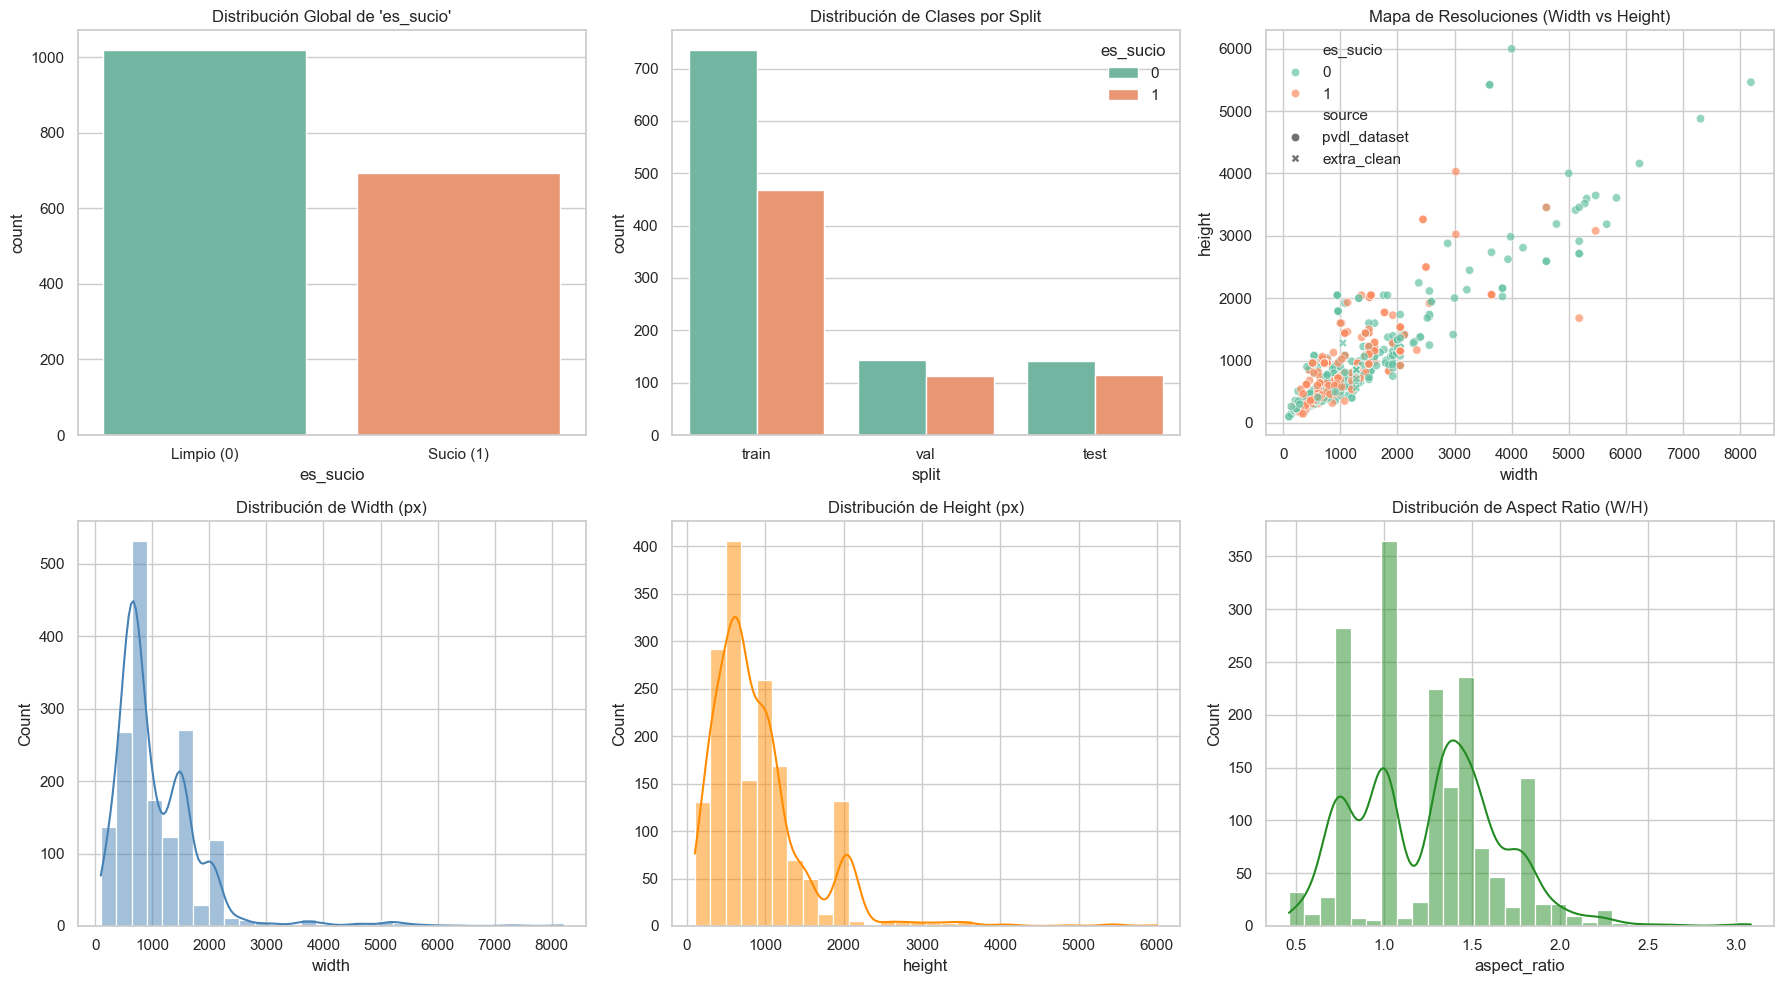

In [14]:
eda_plot_distributions(df)

=== ESTADÍSTICOS DE TAMAÑO Y OUTLIERS (IQR) ===
    Variable        Min        Q1     Mediana           Q3          Max  Outliers_IQR  %_Outliers
       width   100.0000    640.00    787.0000    1500.0000 8.192000e+03            42        2.45
      height   100.0000    500.00    720.0000    1101.0000 6.000000e+03           163        9.51
aspect_ratio     0.4611      1.00      1.3333       1.5006 3.085700e+00            13        0.76
    n_pixels 10000.0000 366518.75 691200.0000 1651500.0000 4.476109e+07            57        3.33


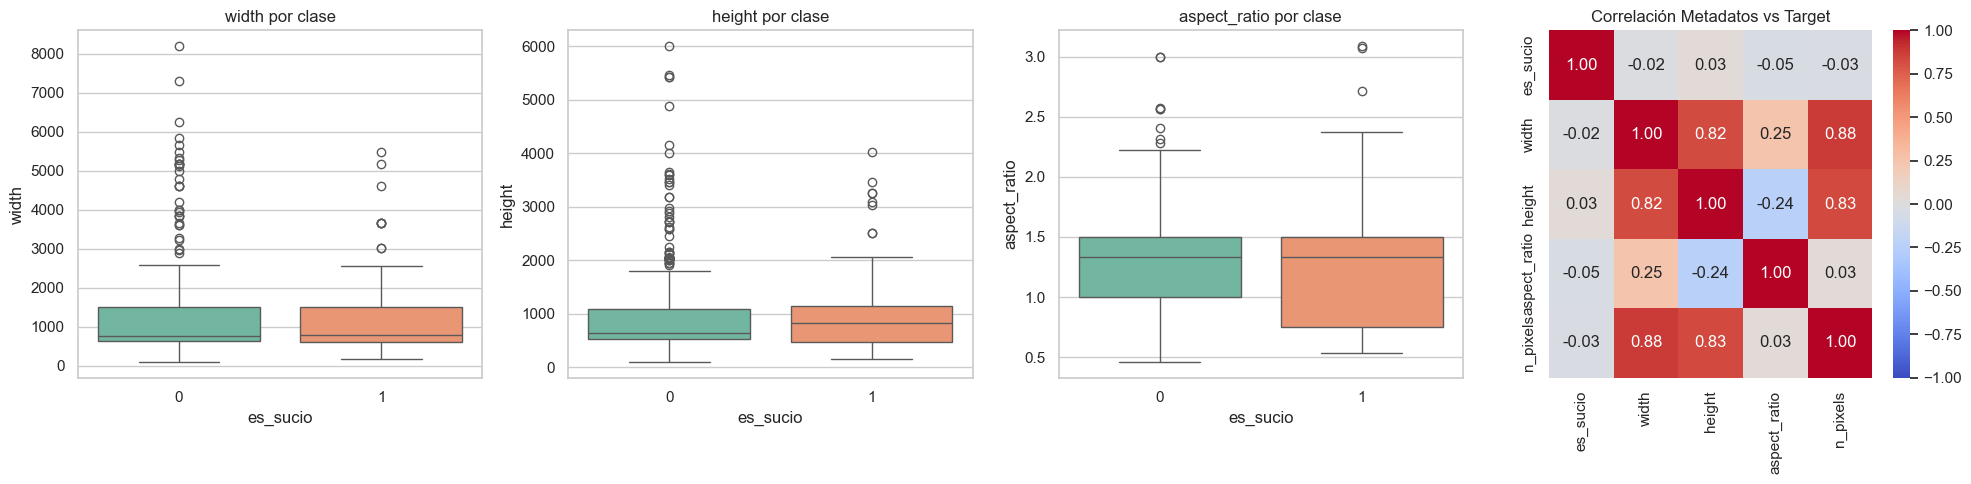

In [15]:
outlier_summary = eda_outliers_and_correlations(df)

Controlar Duplicados

In [ ]:
check_duplicate_images(df)

Duplicados de fila en DataFrame: 0
Duplicados en 'ruta_imagen':     0
Imágenes idénticas (Hash MD5):   0


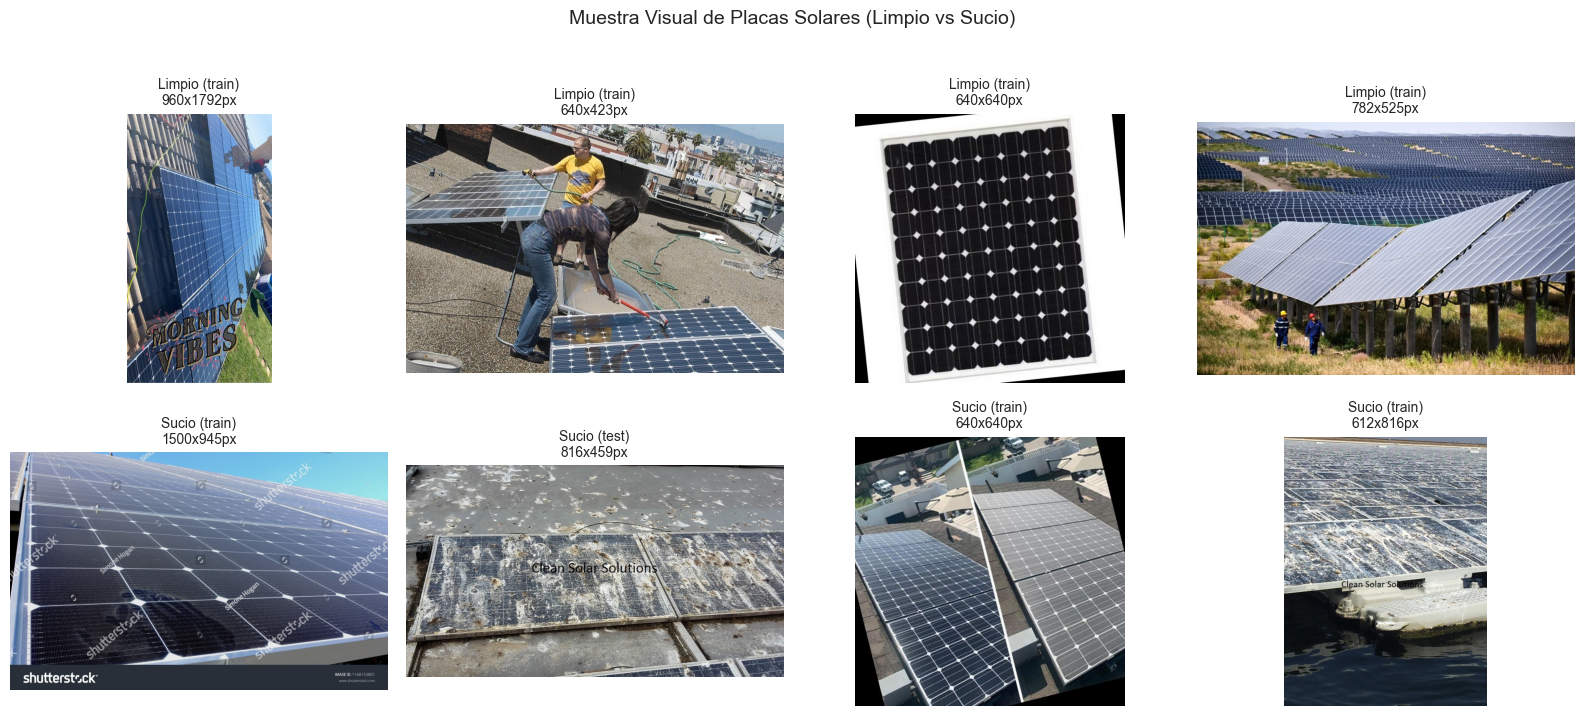

In [9]:
eda_plot_sample_images(df, n_per_class=4)

## 4. Preprocesamiento de Imágenes para Entrenamiento

Como demuestra la matriz de correlación del EDA, los metadatos geométricos (`width`, `height`, `aspect_ratio`) no tienen correlación con si la placa está limpia o sucia. Es imprescindible aplicar **transformaciones a las imágenes**:
- **(Deep Learning / PyTorch)**: Pipeline de `transforms` con redimensionado, *Data Augmentation* en `train` y normalización de canales.

### Preprocesamiento con Tensores y Data Augmentation (`PyTorch`)

In [ ]:
from preprocessing import SolarImageDataset, build_dataloaders, denormalize_image, transform_image

Preprocesamiento Imágenes

In [ ]:
from preprocessing import build_dataloaders

=== DATALOADERS LISTOS (Resolución: (224, 224), Batch: 32) ===
 - Train: 1207 muestras (38 batches)
 - Val:   255 muestras (8 batches)
 - Test:  255 muestras (8 batches)

=== COMPROBACIÓN DE TENSORES ===
Forma del lote de imágenes: torch.Size([32, 3, 224, 224])
Forma del lote de etiquetas: torch.Size([32])
Tipo de dato imágenes: torch.float32
Tipo de dato etiquetas: torch.int64


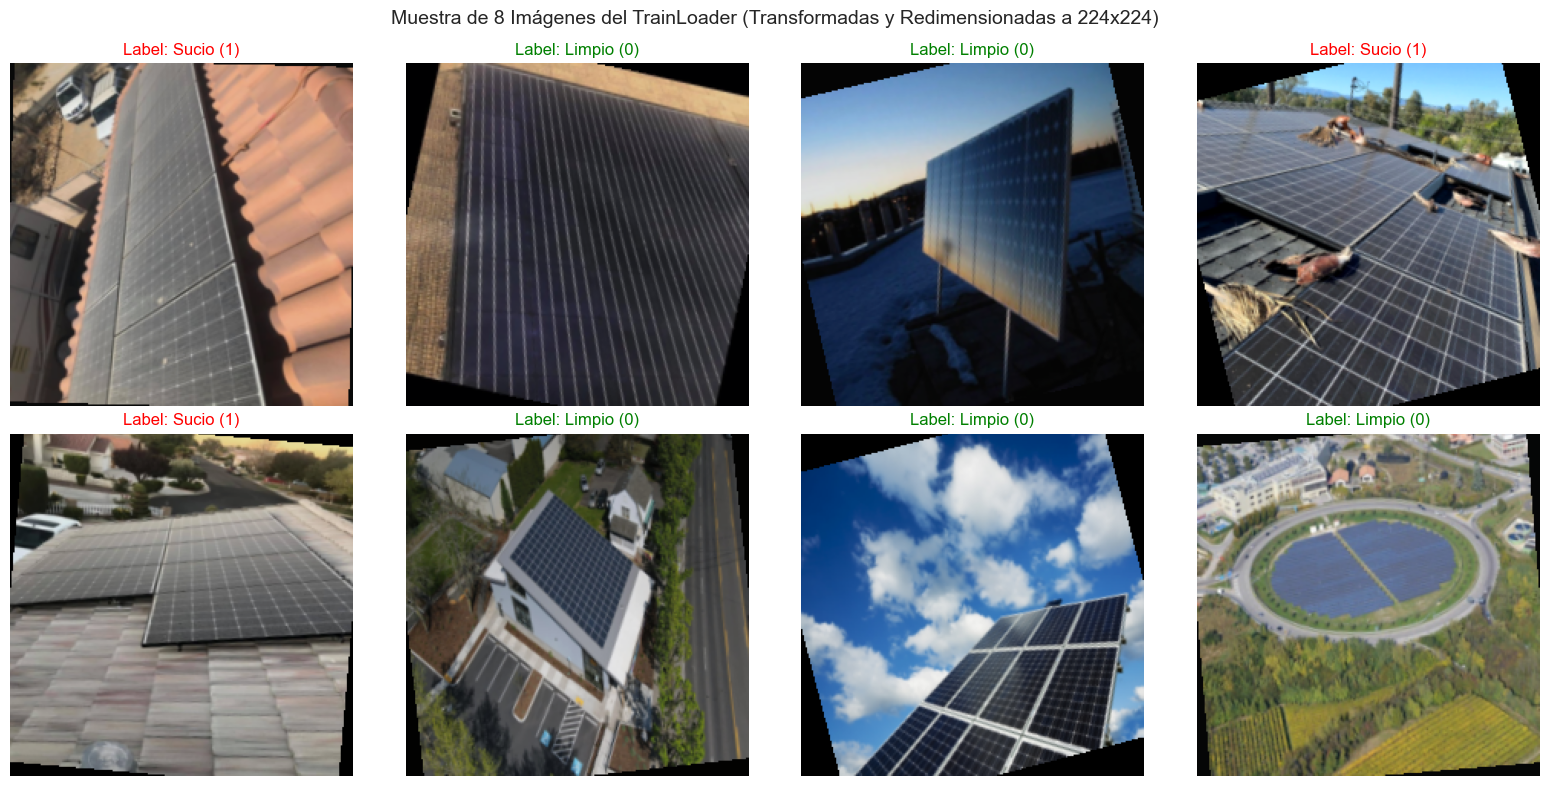

In [ ]:
import matplotlib.pyplot as plt
from preprocessing import denormalize_image

# 1. Construir los DataLoaders
loaders = build_dataloaders(
    df=df,
    root_dir='.',
    image_size=(224, 224),
    batch_size=32,
)

train_loader = loaders['train_loader']

# 2. Extraer un lote (batch) de prueba
images_batch, labels_batch = next(iter(train_loader))

print('\n=== COMPROBACIÓN DE TENSORES ===')
print('Forma del lote de imágenes:', images_batch.shape)
print('Forma del lote de etiquetas:', labels_batch.shape)
print('Tipo de dato imágenes:', images_batch.dtype)
print('Tipo de dato etiquetas:', labels_batch.dtype)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i in range(8):
    img = denormalize_image(images_batch[i])
    label = labels_batch[i].item()
    texto_clase = 'Sucio (1)' if label == 1 else 'Limpio (0)'
    color_borde = 'red' if label == 1 else 'green'

    axes[i].imshow(img)
    axes[i].set_title(f'Label: {texto_clase}', color=color_borde, fontsize=12)
    axes[i].axis('off')

plt.suptitle(
    'Muestra de 8 Imágenes del TrainLoader (Transformadas y Redimensionadas a 224x224)',
    fontsize=14,
    y=0.98,
)
plt.tight_layout()
plt.show()